# 32 — Final regional synthesis: unhedged equity premiums

Compare **Hungary, Poland, Czechia, Romania and Sweden** in **USD and EUR**, on the exact frozen
**October 2014–September 2026** common sample (**144 months**), using the existing **base kernel**.
Keep corrected FX means, zero equity alphas and both **scalar/diagonal BEKK** covariance models.

This notebook consolidates the complete matched pricing catalog and all archived regional robustness
checks. It does **not** fetch data, optimize parameters or change earlier estimates. The main comparison
uses the **same FX-only specification in every country**: constant world/local prices and time-varying
national/other-FX prices, with a free covariance intercept. A separate all-constant benchmark prevents
the attractive conditional decomposition from being confused with the preferred information criterion.

Charts are exported as **PNG and zoomable SVG**, with a self-contained interactive HTML comparison.
[regional_research_synthesis_inputs.json](regional_research_synthesis_inputs.json) pins every upstream
input through the notebook-31 hash chain and fixes the rendering sources.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache/matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import regional_comparison as charts
importlib.reload(charts)
LOCK = ROOT/"regional_research_synthesis_inputs.json"
LOCK_SHA = "006a80daeea5b8fcd28361dd14c8b7ff0e78ce072ec4edba116f314b808fdef9"
def sha(raw): return hashlib.sha256(raw).hexdigest()
assert sha(LOCK.read_bytes()) == LOCK_SHA, "Synthesis lock changed: review the new inputs explicitly."
lock = json.loads(LOCK.read_text())
P31 = ROOT/lock["covariance_targeting"]["root"]
P30 = ROOT/"output/30_regional_FX_targeted_robustness/2014-10_2026-09/targeted_e11bdda3"
P29 = ROOT/"output/29_regional_time_varying_FX_only/2014-10_2026-09/fx_only_606736e5"
P27 = ROOT/"output/27_regional_pricing_errors/2014-10_2026-09/alpha_d0d69f20"
OUT = ROOT/"output/32_regional_research_synthesis/2014-10_2026-09"/f"synthesis_{LOCK_SHA[:8]}"
ASSET = ROOT/"assets/regional-comparison"
OUT.mkdir(parents=True,exist_ok=True); ASSET.mkdir(parents=True,exist_ok=True)
versions = {p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib","ipykernel"]}
plt.rcParams.update({"font.size":10,"axes.grid":True,"grid.alpha":.16,"figure.dpi":110})
pd.set_option("display.max_columns",14)
def verify_inputs():
    raw=(P31/"estimation_manifest.json").read_bytes()
    assert sha(raw)==lock["covariance_targeting"]["manifest_sha256"]
    manifest=json.loads(raw)
    assert (manifest["first"],manifest["last"],manifest["observations_per_fit"],manifest["cases"])==("2014-10","2026-09",144,60)
    expected=manifest["input_file_hashes"].copy()
    expected.update({(P31/n).relative_to(ROOT).as_posix():v for n,v in manifest["outputs"].items()})
    expected[(P31/"estimation_manifest.json").relative_to(ROOT).as_posix()]=lock["covariance_targeting"]["manifest_sha256"]
    expected.update(manifest["engines"]);expected.update(lock["source_locks"]);expected.update(lock["synthesis_sources"])
    for path,value in expected.items():
        assert sha((ROOT/path).read_bytes())==value, f"Changed frozen/synthesis input: {path}"
    return manifest,expected
previous,input_hashes=verify_inputs()
regional=json.loads((ROOT/"regional_dataset_inputs.json").read_text())
months=pd.period_range("2014-10","2026-09",freq="M",name="month")
frames={}
for country in charts.COUNTRIES:
    for currency in ["USD","EUR"]:
        path=ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        d=pd.read_csv(path,index_col=0,float_precision="round_trip");d.index=pd.PeriodIndex(d.index,freq="M",name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all()
        assert sha(path.read_bytes())==input_hashes[path.relative_to(ROOT).as_posix()]
        frames[country,currency]=d

def read(folder,name): return pd.read_csv(folder/name,float_precision="round_trip")
catalog=read(P29,"model_comparison.csv");catalog_premiums=read(P29,"premium_components.csv")
robustness=read(P30,"summary.csv");robust_tests=read(P30,"restriction_tests.csv")
targets=read(P31,"summary.csv");target_premiums=read(P31,"premium_components.csv")
target_tests=read(P31,"restriction_tests.csv");target_inference=read(P31,"inference_audit.csv")
catalog_tests=read(P29,"restriction_tests.csv");catalog_diagnostics=read(P29,"diagnostic_summary.csv")
robust_diagnostics=read(P30,"diagnostic_summary.csv")
alpha_summary=read(P27,"common_comparison.csv");applicability=read(P30,"scenario_applicability.csv")
assert len(catalog)==100 and len(robustness)==160 and len(targets)==60
assert not targets.first_stage_refined.any(), "New free comparators require a fresh consistent catalog before synthesis."
print("Python:",sys.executable);print("Packages:",versions)
print(f"Verified {len(input_hashes):,} upstream files; 100 joint catalog, 160 instrument/influence and 60 targeting cases.")

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Verified 2,588 upstream files; 100 joint catalog, 160 instrument/influence and 60 targeting cases.


## 1. Confirm comparable models, pricing identities and criteria

Each country/investor has ten joint-QML candidates: five pricing restrictions × two covariance models.
Rank AIC/BIC **within** that same country/investor sample. Do not rank likelihoods across countries,
or use stage-two parameter counts to rank the estimated covariance targets.

$$\boxed{\mu_{i,t}^{unhedged}=\lambda_W(t)H_{iW,t}
+\lambda_{FX,n}(t)H_{i,FX,n,t}+\lambda_{FX,o}(t)H_{i,FX,o,t}
+\lambda_{L,i}(t)H_{ii,t}.}$$

The displayed contribution is a **monthly price × conditional covariance product**. Its sample
average is $T^{-1}\sum_t\lambda_t H_t$, including their interaction; it is not the product of average
price and average covariance. All equity alphas remain zero. Units: **monthly log percentage points**;
these are expected excess-return components, not realized return attribution.

In [2]:
keys=["country","perspective","covariance"]
component_cols=[c+"_premium_pp" for c in charts.COMPONENTS]
identity_rows=[]
for frame,groupcols,label in [(catalog_premiums,keys+["stage"],"joint catalog"),(target_premiums,keys+["target_kind"],"targeting")]:
    assert frame.equity_alpha_pp.eq(0).all()
    for case,g in frame.groupby(groupcols,sort=False):
        g=g.sort_values("month");assert g.month.tolist()==months.astype(str).tolist()
        err=np.max(np.abs(g[component_cols].sum(axis=1)-g.fitted_mean_pp))
        assert err<1e-10
        for c in charts.COMPONENTS:
            np.testing.assert_allclose(g[c+"_price"]*g[c+"_covariance_pp2"],g[c+"_premium_pp"],atol=1e-10,rtol=1e-12)
        identity_rows.append({"source":label,"case":"/".join(map(str,case)),"months":len(g),"maximum_identity_error_pp":err})
identity_audit=pd.DataFrame(identity_rows)
assert catalog.groupby(["country","perspective"]).size().eq(10).all()
np.testing.assert_allclose(catalog.AIC,2*catalog.parameters-2*catalog.loglik,atol=1e-9,rtol=0)
np.testing.assert_allclose(catalog.BIC,np.log(144)*catalog.parameters-2*catalog.loglik,atol=1e-9,rtol=0)
for _,g in catalog.groupby(["country","perspective"]):
    assert g.loc[g.BIC_rank_all10.eq(1),"BIC"].iloc[0] <= g.BIC.min()+1e-9
    assert g.loc[g.AIC_rank_all10.eq(1),"AIC"].iloc[0] <= g.AIC.min()+1e-9
winners=pd.concat([catalog.loc[catalog[f"{criterion}_rank_all10"].eq(1)].assign(criterion=criterion) for criterion in ["AIC","BIC"]],ignore_index=True)
print("Winner counts (within country/investor):")
display(winners.groupby(["criterion","model","covariance"]).size().rename("cases"))
display(winners[["country","perspective","criterion","model","covariance","inference_ready_QML","inference_reason_QML"]])
# Confirm every free reference remains exactly the FX-only catalog fit.
for row in targets.query("target_kind == 'free'").itertuples():
    r=catalog.query("country == @row.country and perspective == @row.perspective and covariance == @row.covariance and stage == 5").iloc[0]
    assert abs(r.loglik-row.loglik)<1e-8

Winner counts (within country/investor):


criterion  model  covariance
AIC        S1     diagonal       1
                  scalar         1
           S2     diagonal       2
                  scalar         5
           S3     diagonal       1
BIC        S1     scalar        10
Name: cases, dtype: int64

,country,perspective,criterion,model,covariance,inference_ready_QML,inference_reason_QML
0,HU,USD,AIC,S1,diagonal,False,parameter bound; ill-conditioned curvature
1,HU,EUR,AIC,S2,scalar,True,numerically ready
2,PL,USD,AIC,S2,diagonal,False,parameter bound; ill-conditioned curvature
3,PL,EUR,AIC,S2,scalar,True,numerically ready
4,CZ,USD,AIC,S1,scalar,True,numerically ready
5,CZ,EUR,AIC,S3,diagonal,False,parameter bound; ill-conditioned curvature
6,RO,USD,AIC,S2,diagonal,False,parameter bound
7,RO,EUR,AIC,S2,scalar,True,numerically ready
8,SE,USD,AIC,S2,scalar,True,numerically ready
9,SE,EUR,AIC,S2,scalar,True,numerically ready


## 2. Side-by-side unhedged regional decomposition

Use the **common FX-only free-intercept reference**, not a different selected model in each country.
The upper row is scalar BEKK; the lower row is diagonal BEKK. USD and EUR are separate investor
perspectives. All four panels share the same vertical scale. **†** identifies fits with ordinary
inference withheld: the point estimates are descriptive, and a large bar is not a significance test.
These flags concern ordinary parameter/risk-price inference; the bars have no confidence intervals.

Bars split world, **national FX** (HUF/PLN/CZK/RON/SEK), **other FX** (EUR for a USD investor; USD
for a EUR investor) and national local risk. Diamonds are net fitted means; hollow circles are observed
mean excess returns. Zero-alpha conditional QML does not impose that these sample means match.

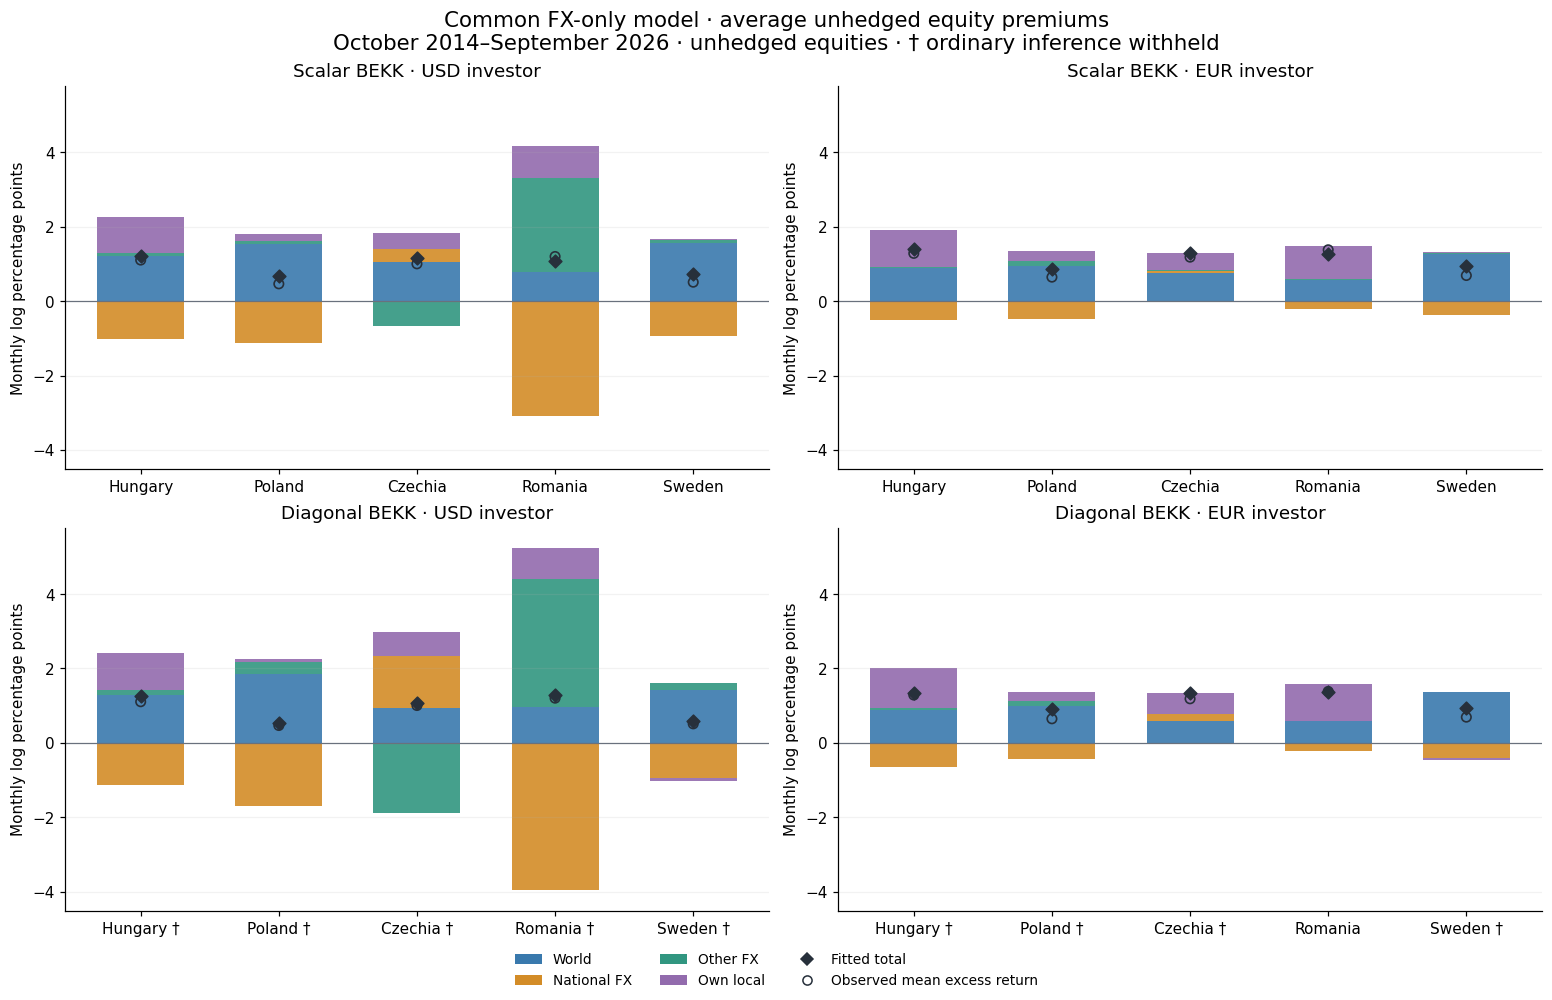

world_premium_pp  national_FX_premium_pp  \
country perspective covariance                                             
HU      USD         scalar                 1.213                  -1.025   
                    diagonal               1.276                  -1.136   
        EUR         scalar                 0.885                  -0.508   
                    diagonal               0.894                  -0.656   
PL      USD         scalar                 1.536                  -1.135   
                    diagonal               1.839                  -1.711   
        EUR         scalar                 0.956                  -0.484   
                    diagonal               1.001                  -0.448   
CZ      USD         scalar                 1.063                   0.351   
                    diagonal               0.949                   1.387   
        EUR         scalar                 0.753                   0.064   
                    diagonal               0.591                   0.180   
RO      USD         scalar                 0.796                  -3.088   
                    diagonal               0.956                  -3.959   
        EUR         scalar                 0.573                  -0.213   
                    diagonal               0.584                  -0.213   
SE      USD         scalar                 1.553                  -0.926   
                    diagonal               1.414                  -0.950   
        EUR         scalar                 1.269                  -0.371   
                    diagonal               1.353                  -0.403   

                                other_FX_premium_pp  local_premium_pp  \
country perspective covariance                                          
HU      USD         scalar                    0.090             0.948   
                    diagonal                  0.146             0.987   
        EUR         scalar                    0.034             0.988   
                    diagonal                  0.038             1.066   
PL      USD         scalar                    0.075             0.205   
                    diagonal                  0.322             0.096   
        EUR         scalar                    0.129             0.262   
                    diagonal                  0.121             0.236   
CZ      USD         scalar                   -0.677             0.411   
                    diagonal                 -1.897             0.634   
        EUR         scalar                    0.013             0.472   
                    diagonal                 -0.004             0.576   
RO      USD         scalar                    2.504             0.863   
                    diagonal                  3.440             0.838   
        EUR         scalar                    0.014             0.893   
                    diagonal                  0.013             0.972   
SE      USD         scalar                    0.095             0.021   
                    diagonal                  0.199            -0.077   
        EUR         scalar                    0.028             0.013   
                    diagonal                  0.024            -0.050   

                                fitted_mean_pp  observed_mean_excess_pp  \
country perspective covariance                                            
HU      USD         scalar               1.225                    1.105   
                    diagonal             1.272                    1.105   
        EUR         scalar               1.399                    1.285   
                    diagonal             1.343                    1.285   
PL      USD         scalar               0.681                    0.466   
                    diagonal             0.545                    0.466   
        EUR         scalar               0.863                    0.646   
                    diagonal             0.911                    0.646   
CZ

In [3]:
fx_premiums=catalog_premiums.query("stage == 5").copy()
availability=catalog.query("stage == 5")[keys+["inference_ready_QML","inference_reason_QML"]].rename(columns={"inference_ready_QML":"inference_ready","inference_reason_QML":"reason"})
means=charts.average_table(fx_premiums,frames,availability)
asset_files=charts.mean_comparison(means,ASSET,"01_unhedged_mean_comparison","Common FX-only model · average unhedged equity premiums")
display(means.set_index(keys)[component_cols+["fitted_mean_pp","observed_mean_excess_pp","mean_pricing_residual_pp","inference_ready"]].round(3))

## 3. Common time series, in the paper's three-row format

Rows show **world**, **total currency** (national + other FX) and **own local** contributions. The two
FX components remain separate in the mean chart, exported tables and interactive viewer. Columns use
the same dates and the same vertical scale **within each row**. Thin lines are monthly estimates;
thick lines are trailing 12-month averages, requiring 12 complete observations. Gray bands mark
2020 and 2022–23; they identify the periods examined by the existing influence checks.

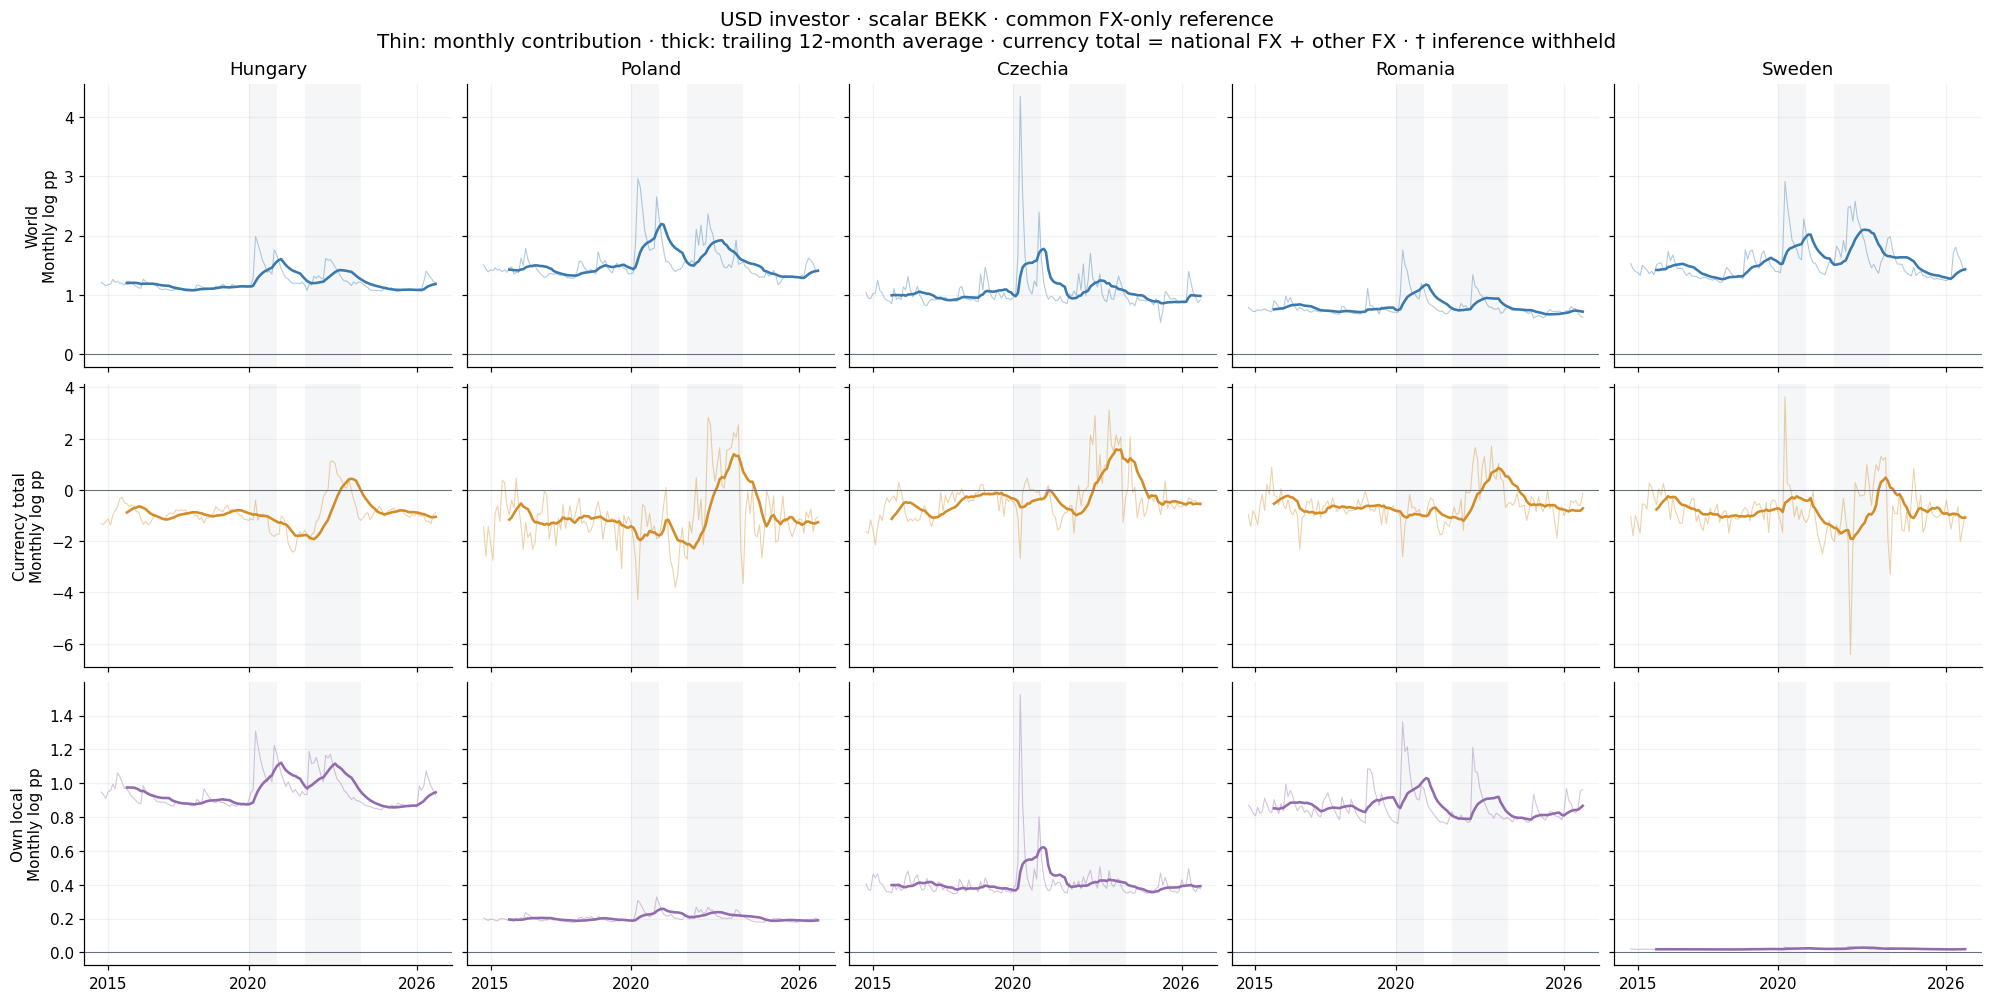

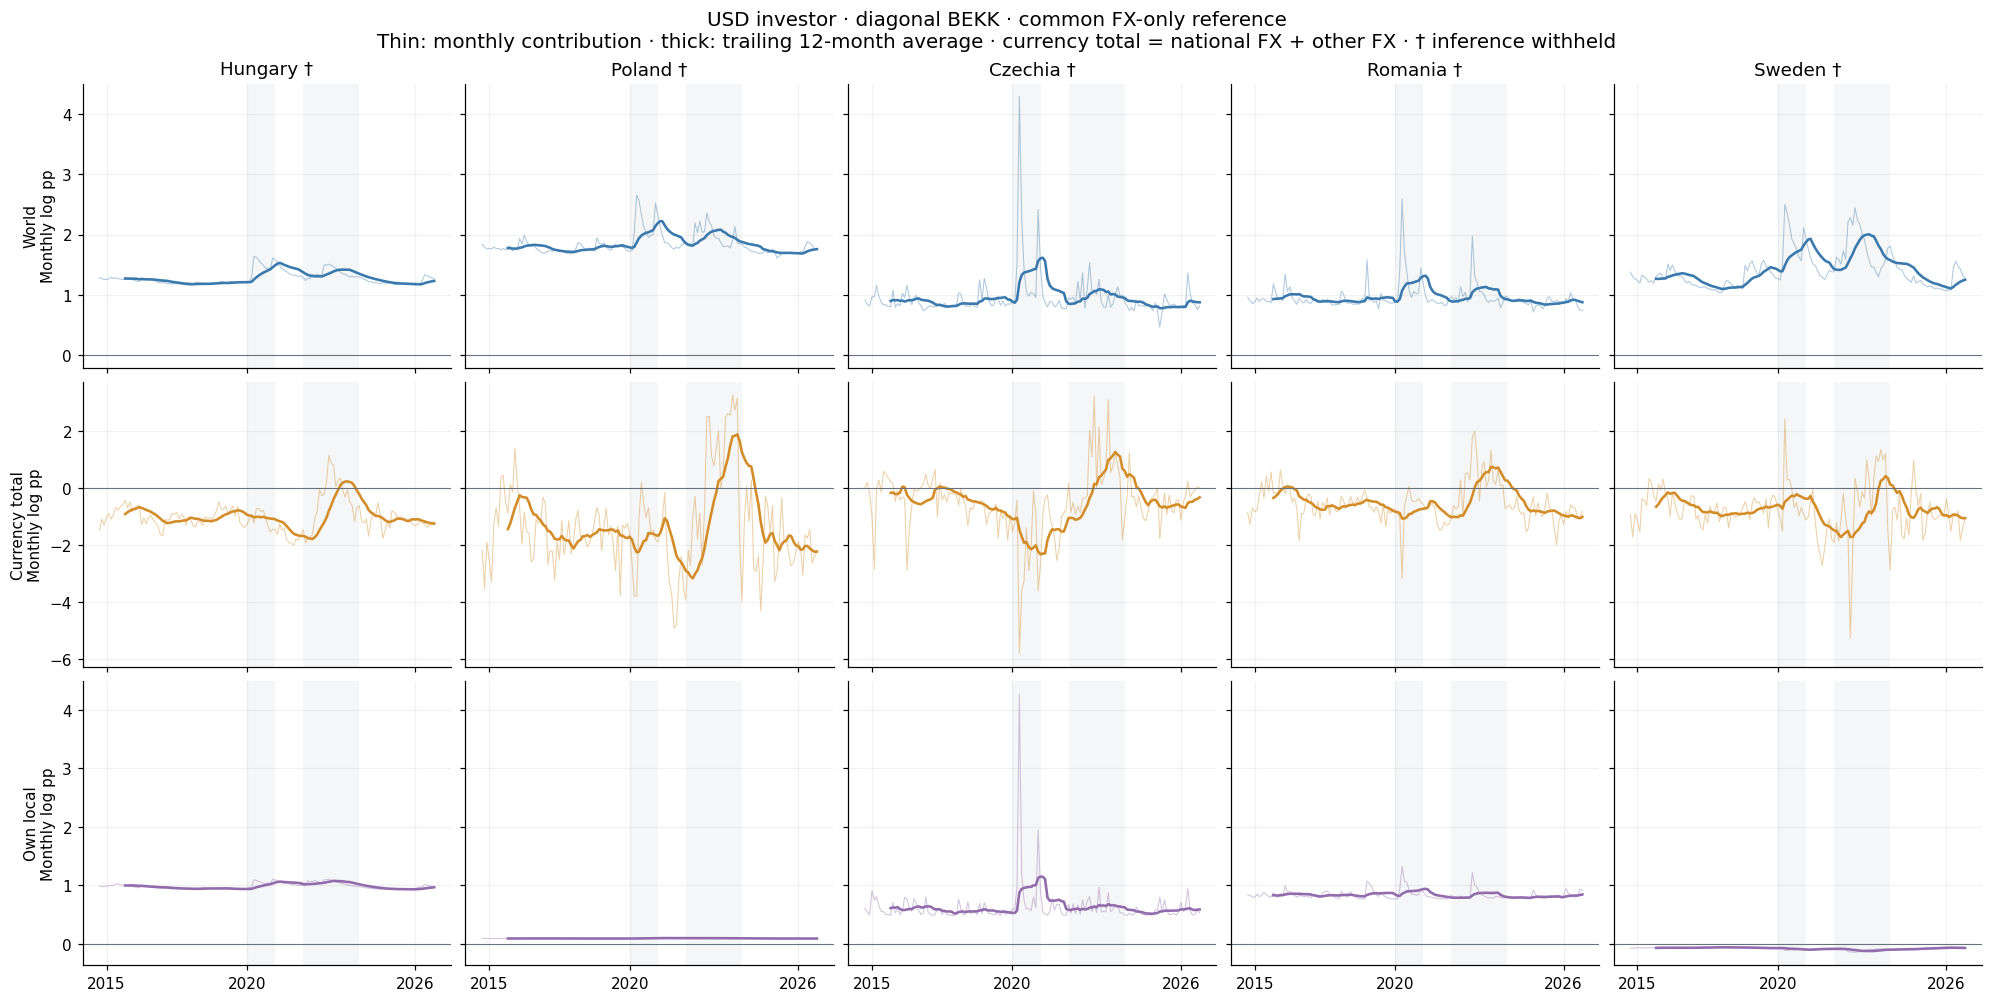

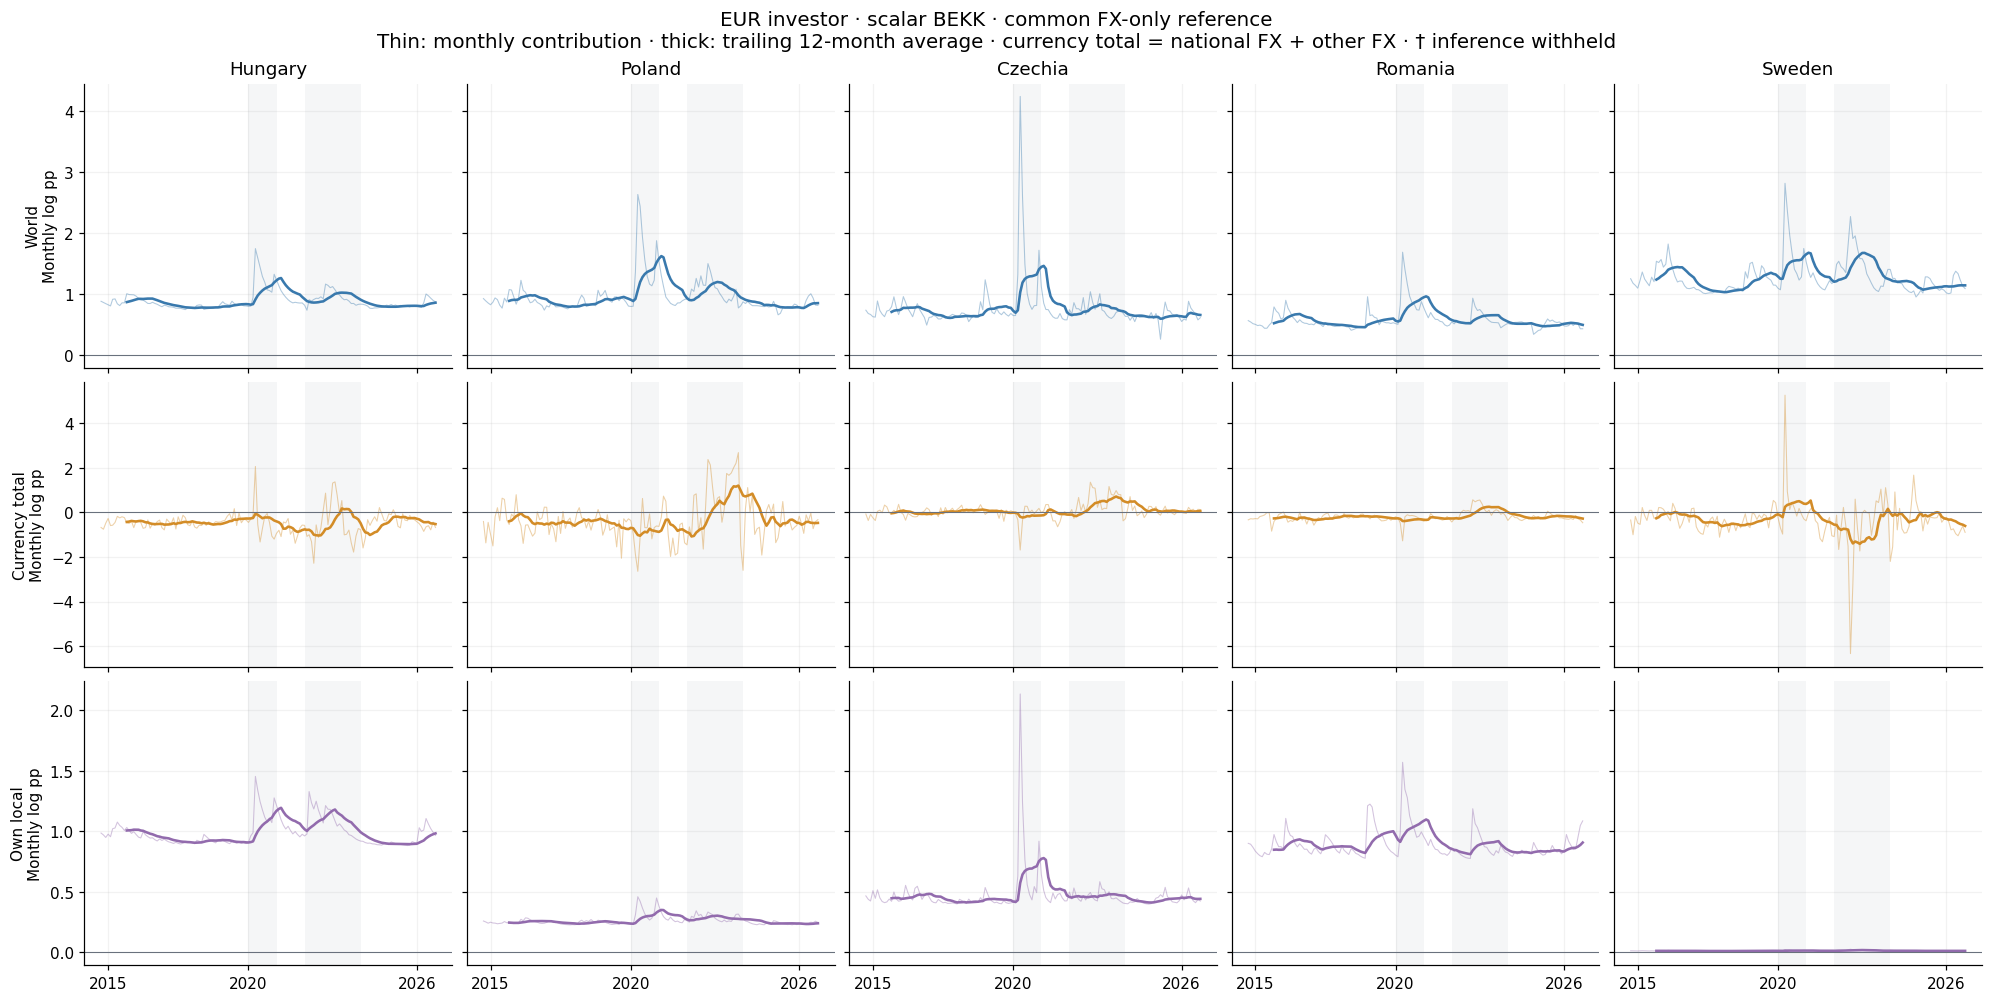

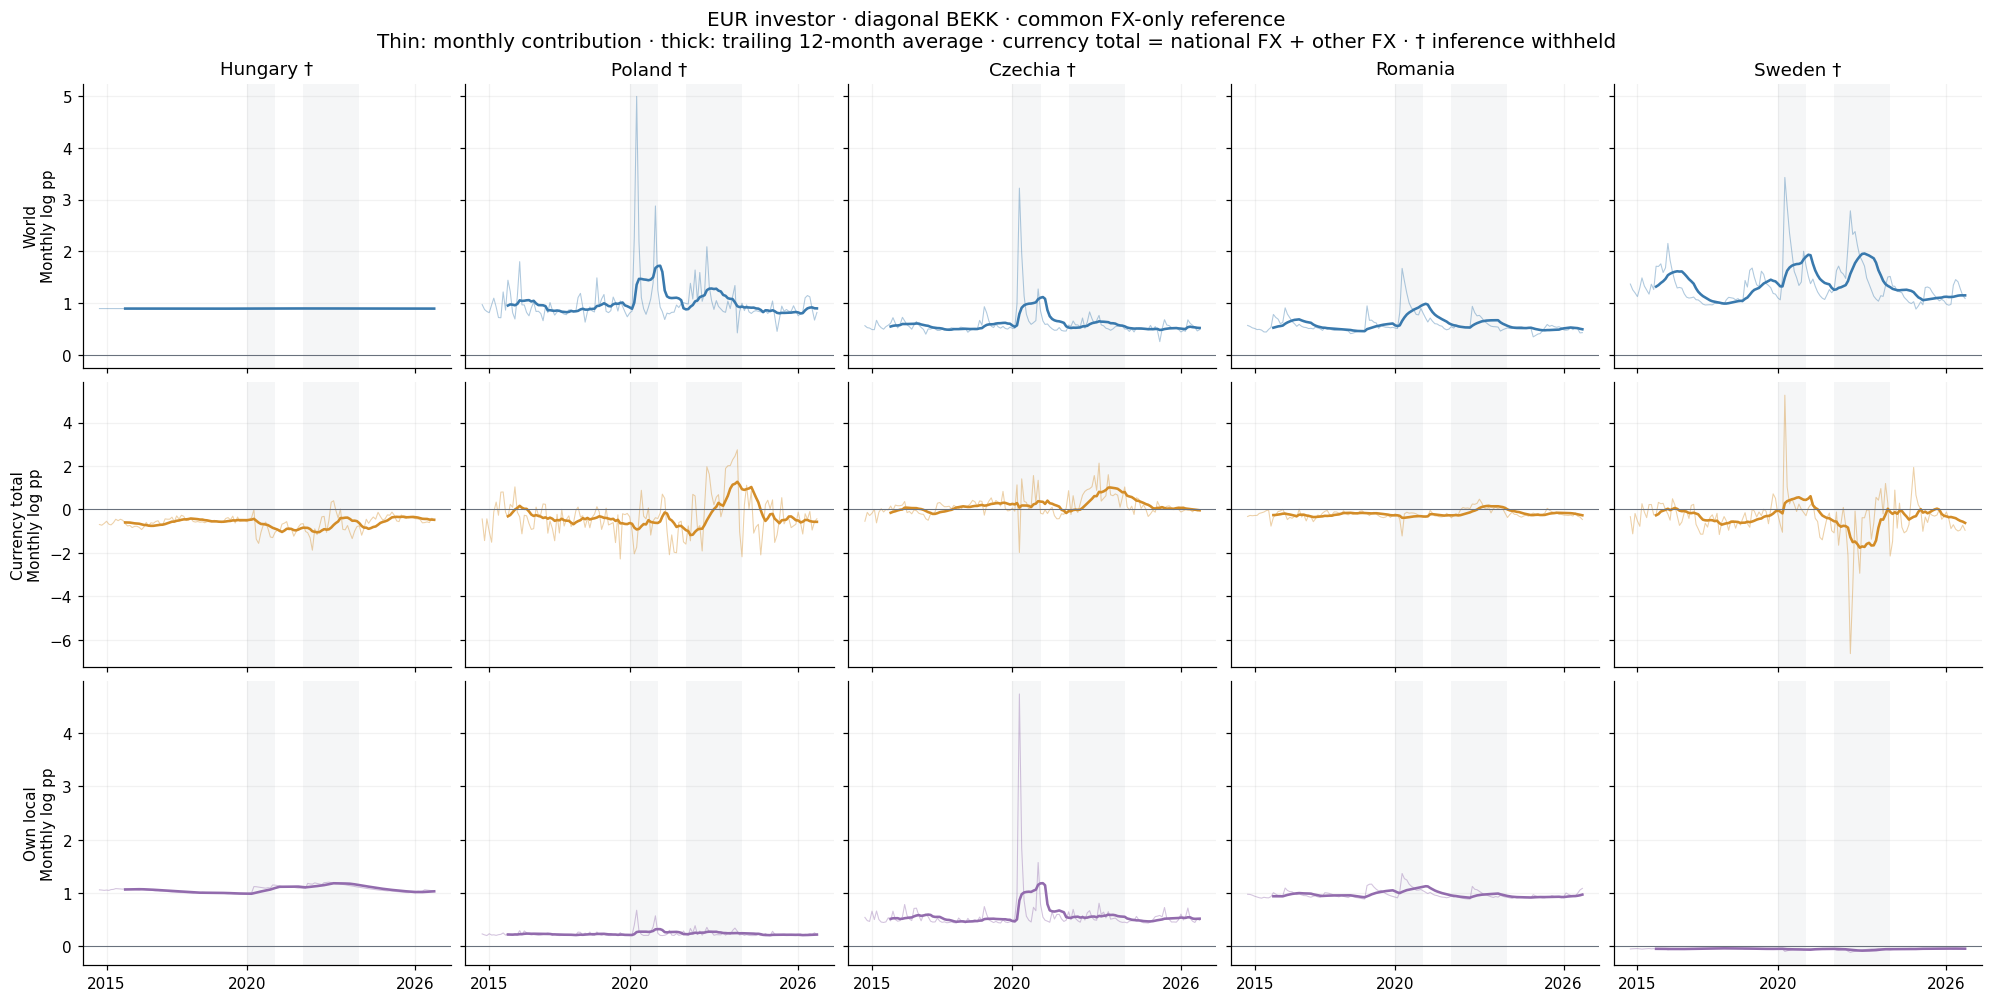

In [4]:
for currency in ["USD","EUR"]:
    for cov in ["scalar","diagonal"]:
        asset_files+=charts.monthly_comparison(fx_premiums,availability,currency,cov,ASSET,f"02_unhedged_{currency}_{cov}")

## 4. Keep the simpler benchmark and all robustness evidence visible

The FX-only branch supplies a common decomposition; it is not automatically the best model. The
all-constant S1 benchmark below uses both covariance models, with its own inference flags. The full
catalog remains available in the viewer.

The sign-sensitivity ranges include all reported point estimates, including numerically irregular
fits; they are not confidence intervals or a pooled cross-country significance test.

Instrument/influence checks include lag-three inflation timing, national gap levels, regime removal,
removal of direct US CPI, exclusion of carried-CPI likelihood terms, and 2020/2022–23 calendar weights.
State paths always retain all 144 months; zero likelihood weight is not a deleted month. Regime-removal
runs outside Czechia are exact baseline aliases; 2008–09 lies outside the common window and is not an
estimated robustness result. Primary p-values use QML/HAC-0; show HAC 3/6/12 sensitivity alongside them.
All tests are exploratory; the two FX-block Holm families do not correct across all countries or checks.

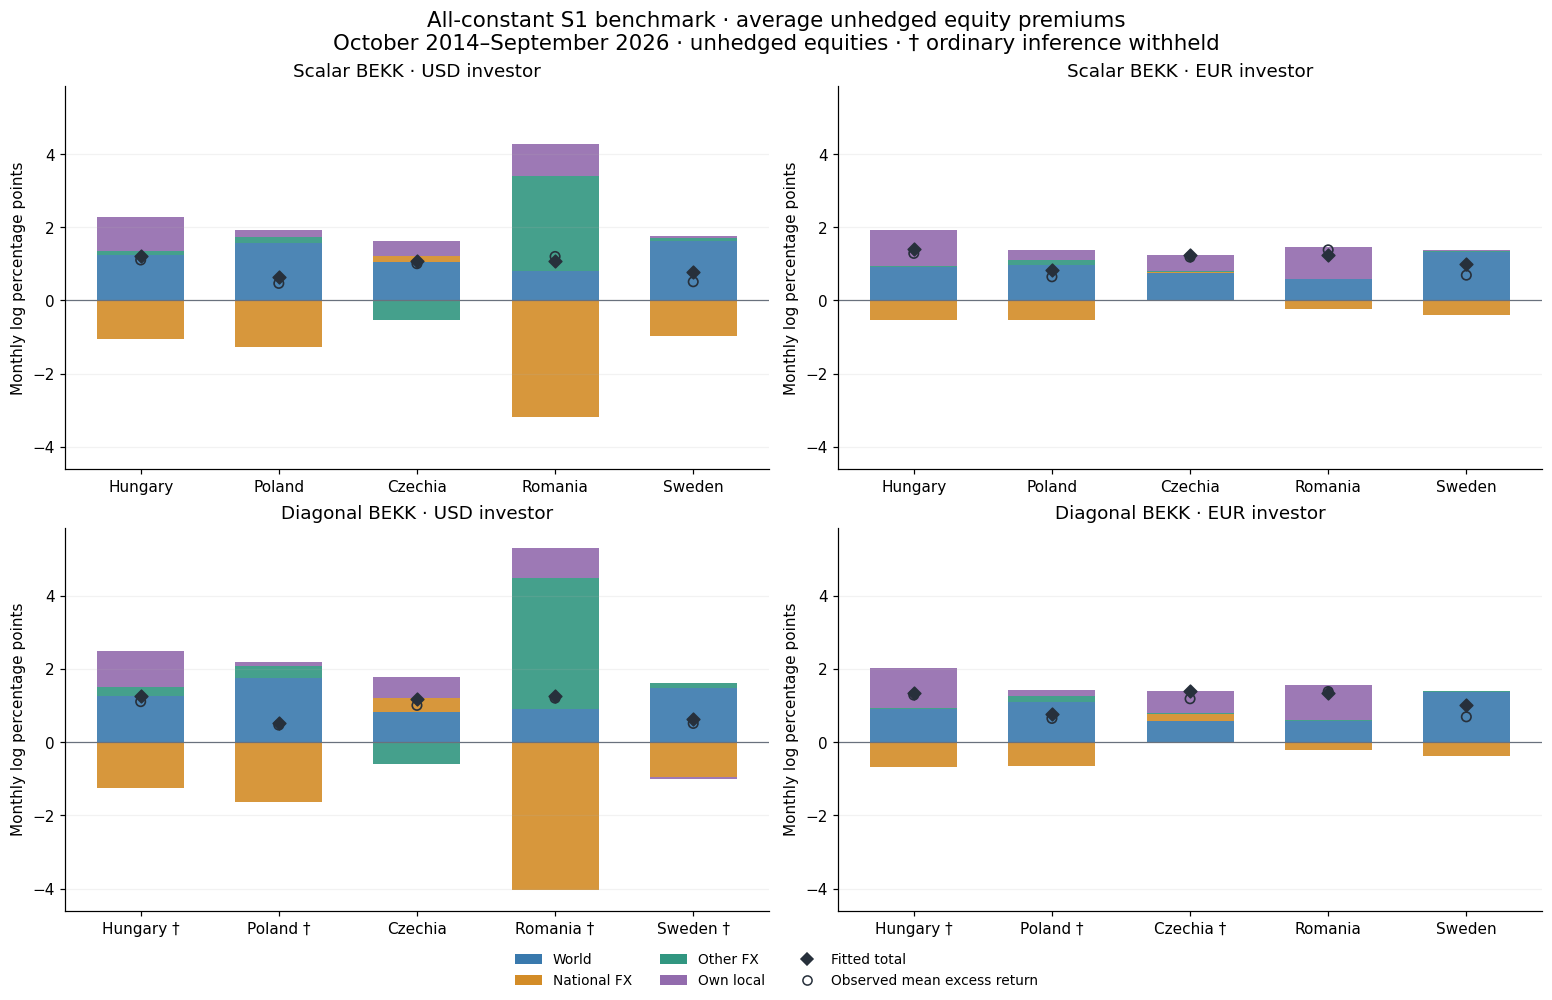

,covariance,variant,cases,primary_usable,aliases,scored_months_min,scored_months_max
0,scalar,baseline,10,10,0,144,144
1,scalar,lag3,10,10,0,144,144
2,scalar,gap_level,10,10,0,144,144
3,scalar,no_regime,10,10,8,144,144
4,scalar,no_US_CPI,10,10,0,144,144
5,scalar,CPI_terms0,10,10,0,142,143
6,scalar,block_2020,10,10,0,132,132
7,scalar,block_2022_23,10,10,0,120,120
8,diagonal,baseline,10,1,0,144,144
9,diagonal,lag3,10,1,0,144,144


variant              CPI_terms0  baseline  block_2020  block_2022_23  \
country perspective                                                    
CZ      EUR              0.6238    0.6480      0.4362         0.1742   
        USD              0.3445    0.3833      0.3657         0.0593   
HU      EUR              0.3562    0.3730      0.4132         0.2432   
        USD              0.5225    0.5439      0.5369         0.2027   
PL      EUR              0.5455    0.5574      0.5709         0.4233   
        USD              0.5663    0.5846      0.5671         0.4251   
RO      EUR              0.3917    0.4011      0.4049         0.3142   
        USD              0.3514    0.3677      0.2758         0.1910   
SE      EUR              0.0201    0.0203      0.1685         0.0381   
        USD              0.0738    0.0680      0.3521         0.0598   

variant              gap_level    lag3  no_US_CPI  no_regime  
country perspective                                           
CZ      EUR             0.3100  0.5094     0.8933     0.5607  
        USD             0.0462  0.4644     0.7191     0.3580  
HU      EUR             0.3939  0.4285     0.5774     0.3730  
        USD             0.4808  0.2459     0.6582     0.5439  
PL      EUR             0.5853  0.4295     0.6559     0.5574  
        USD             0.5377  0.4723     0.5928     0.5846  
RO      EUR             0.5599  0.5454     0.5776     0.4011  
        USD             0.3115  0.2534     0.7961     0.3677  
SE      EUR             0.0691  0.0549     0.0489     0.0203  
        USD             0.0673  0.0168     0.0818     0.0680

FX_constancy_p_QML  FX_constancy_p_min  \
country perspective covariance                                           
HU      USD         scalar                  0.5439              0.0057   
                    diagonal                   NaN                 NaN   
        EUR         scalar                  0.3730              0.0008   
                    diagonal                   NaN                 NaN   
PL      USD         scalar                  0.5846              0.0032   
                    diagonal                   NaN                 NaN   
        EUR         scalar                  0.5574              0.0007   
                    diagonal                   NaN                 NaN   
CZ      USD         scalar                  0.3833              0.0020   
                    diagonal                   NaN                 NaN   
        EUR         scalar                  0.6480              0.0039   
                    diagonal                   NaN                 NaN   
RO      USD         scalar                  0.3677              0.0015   
                    diagonal                   NaN                 NaN   
        EUR         scalar                  0.4011              0.0035   
                    diagonal                0.4002              0.0065   
SE      USD         scalar                  0.0680              0.0000   
                    diagonal                   NaN                 NaN   
        EUR         scalar                  0.0203              0.0000   
                    diagonal                   NaN                 NaN   

                                FX_constancy_p_max  available_bandwidth_tests  \
country perspective covariance                                                  
HU      USD         scalar                  0.5439                          4   
                    diagonal                   NaN                          0   
        EUR         scalar                  0.3730                          4   
                    diagonal                   NaN                          0   
PL      USD         scalar                  0.5846                          4   
                    diagonal                   NaN                          0   
        EUR         scalar                  0.5574                          4   
                    diagonal                   NaN                          0   
CZ      USD         scalar                  0.3833                          4   
                    diagonal                   NaN                          0   
        EUR         scalar                  0.6480                          4   
                    diagonal                   NaN                          0   
RO      USD         scalar                  0.3677                          4   
                    diagonal                   NaN                          0   
        EUR         scalar                  0.4011                          4   
                    diagonal                0.4002                          4   
SE      USD         scalar                  0.0680                          4   
                    diagonal                   NaN                          0   
        EUR         scalar                  0.0203                          4   
                    diagonal                   NaN                          0   

                                inference_ready_QML  
country perspective covariance                       
HU      USD         scalar                     True  
                    diagonal                  False  
        EUR         scalar                     True  
                    diagonal                  False  
PL      USD         scalar                     True  
                    diagonal                  False  
        EUR         scalar                     True  
                    diagonal                  False  
CZ      USD         scalar                     True  
                    diagon

,country,perspective,variant,applicable,baseline_alias,affected_likelihood_months,reason
0,HU,USD,baseline,True,False,0,baseline reference
1,HU,USD,lag3,True,False,0,active sensitivity
2,HU,USD,gap_level,True,False,0,active sensitivity
3,HU,USD,no_regime,False,True,0,no varying regime column; exact baseline alias
4,HU,USD,no_US_CPI,True,False,0,active sensitivity
...,...,...,...,...,...,...,...
85,SE,EUR,no_US_CPI,True,False,0,active sensitivity
86,SE,EUR,CPI_terms0,True,False,1,active sensitivity
87,SE,EUR,block_2020,True,False,12,active sensitivity
88,SE,EUR,block_2022_23,True,False,24,active sensitivity


In [5]:
s1_premiums=catalog_premiums.query("stage == 1")
s1_availability=catalog.query("stage == 1")[keys+["inference_ready_QML","inference_reason_QML"]].rename(columns={"inference_ready_QML":"inference_ready","inference_reason_QML":"reason"})
s1_means=charts.average_table(s1_premiums,frames,s1_availability)
asset_files+=charts.mean_comparison(s1_means,ASSET,"03_constant_price_benchmark","All-constant S1 benchmark · average unhedged equity premiums")
robust_constancy=robust_tests.query("restriction == 'FX prices constant'").copy()
robustness_coverage=robustness.groupby(["covariance","variant"],sort=False).agg(cases=("country","size"),primary_usable=("inference_ready_QML","sum"),aliases=("baseline_alias","sum"),scored_months_min=("scored_months","min"),scored_months_max=("scored_months","max")).reset_index()
display(robustness_coverage)
display(robustness.query("covariance == 'scalar'").pivot(index=["country","perspective"],columns="variant",values="FX_constancy_p_QML").round(4))
display(robustness.query("variant == 'baseline'").set_index(keys)[["FX_constancy_p_QML","FX_constancy_p_min","FX_constancy_p_max","available_bandwidth_tests","inference_ready_QML"]].round(4))
display(applicability)

## 5. Covariance targets, numerical regularity and pricing adequacy

Compare the free intercept with the uncentered fitted-innovation second moment and centered-return
covariance, both using denominator $T$. Primary targeted uncertainty propagates target estimation
through stacked estimating equations. The target-fixed calculation is only a sensitivity. Boundary
or unstable fits retain point estimates but **no ordinary Wald p-values**. No two-step AIC/BIC or
ordinary LR comparisons are reported.

Pricing-error intercept tests come from notebook 27's **S3/S4** designs. They are evidence about those
specifications, not a dedicated alpha test of FX-only. Non-rejection does not establish correct pricing.
Residual tests and numerical failures remain attached to the original catalog and robustness tables.

In [6]:
target_coverage=targets.groupby(["target_kind","covariance"],sort=False).agg(cases=("country","size"),primary_usable=("primary_inference_ready","sum"),minimum_PD_margin=("PD_margin","min")).reset_index()
display(target_coverage)
display(targets.query("covariance == 'scalar'").pivot(index=["country","perspective"],columns="target_kind",values="FX_constancy_p_primary").round(4))
display(target_inference.query("HAC_lag == 0").groupby(["target_kind","covariance","method","ready"]).size().rename("cases"))
display(alpha_summary[["country","perspective","covariance","local_form","joint_zero_alpha_p_HAC0","joint_zero_alpha_p_HAC3","joint_zero_alpha_p_HAC6","joint_zero_alpha_p_HAC12","numerical_inference_ready","inference_reason"]].round(4))
# Track average-contribution signs and changes across instrument/influence and target choices.
robust_premiums=read(P30,"premium_components.csv")
robust_mean=robust_premiums.groupby(keys+["variant"],sort=False)[component_cols+["fitted_mean_pp"]].mean().reset_index()
target_mean=target_premiums.groupby(keys+["target_kind"],sort=False)[component_cols+["fitted_mean_pp"]].mean().reset_index()
sensitivity=[]
for tag,g in robust_mean.groupby(keys,sort=False):
    for field in component_cols:
        base=g.loc[g.variant.eq("baseline"),field].iloc[0]
        alternatives=g.loc[~g.variant.eq("baseline"),field]
        h=target_mean
        for k,v in zip(keys,tag):h=h.loc[h[k].eq(v)]
        for family,values in [("instrument/influence",alternatives),("covariance targets",h.loc[h.target_kind.ne("free"),field])]:
            sensitivity.append({**dict(zip(keys,tag)),"component":field.replace("_premium_pp",""),"family":family,"baseline_mean_pp":base,"minimum_mean_pp":values.min(),"maximum_mean_pp":values.max(),"same_sign_as_baseline":bool((np.sign(values)==np.sign(base)).all())})
sign_sensitivity=pd.DataFrame(sensitivity)
display(sign_sensitivity.query("component == 'national_FX'").set_index(keys+["family"]).round(3))

,target_kind,covariance,cases,primary_usable,minimum_PD_margin
0,free,scalar,10,10,3.323595e-03
1,innovations,scalar,10,10,3.290890e-03
2,returns,scalar,10,10,3.119914e-03
3,free,diagonal,10,1,-9.863956e-09
4,innovations,diagonal,10,1,-8.349365e-14
5,returns,diagonal,10,1,-3.993253e-14


target_kind            free  innovations  returns
country perspective                              
CZ      EUR          0.6480       0.6913   0.6264
        USD          0.3833       0.4504   0.3602
HU      EUR          0.3730       0.3639   0.2676
        USD          0.5439       0.5224   0.4191
PL      EUR          0.5574       0.5523   0.4389
        USD          0.5846       0.5855   0.4778
RO      EUR          0.4011       0.4047   0.3056
        USD          0.3677       0.3602   0.2324
SE      EUR          0.0203       0.0154   0.0018
        USD          0.0680       0.0544   0.0136

target_kind  covariance  method           ready
free         diagonal    joint_QML        False     9
                                          True      1
             scalar      joint_QML        True     10
innovations  diagonal    target_adjusted  False     9
                                          True      1
                         target_fixed     False     9
                                          True      1
             scalar      target_adjusted  True     10
                         target_fixed     True     10
returns      diagonal    target_adjusted  False     9
                                          True      1
                         target_fixed     False     9
                                          True      1
             scalar      target_adjusted  True     10
                         target_fixed     True     10
Name: cases, dtype: int64

,country,perspective,covariance,local_form,joint_zero_alpha_p_HAC0,joint_zero_alpha_p_HAC3,joint_zero_alpha_p_HAC6,joint_zero_alpha_p_HAC12,numerical_inference_ready,inference_reason
0,HU,USD,scalar,constant_local,0.8185,0.8494,0.8311,0.7853,True,numerically ready
1,HU,USD,diagonal,constant_local,NaN,NaN,NaN,NaN,False,parameter bound; ill-conditioned curvature
2,HU,USD,scalar,time_varying_local,0.8394,0.8677,0.8392,0.7809,True,numerically ready
3,HU,USD,diagonal,time_varying_local,NaN,NaN,NaN,NaN,False,parameter bound; ill-conditioned curvature
4,HU,EUR,scalar,constant_local,0.8483,0.8889,0.8603,0.7233,True,numerically ready
5,HU,EUR,diagonal,constant_local,NaN,NaN,NaN,NaN,False,parameter bound; ill-conditioned curvature
6,HU,EUR,scalar,time_varying_local,0.8737,0.9083,0.8766,0.7247,True,numerically ready
7,HU,EUR,diagonal,time_varying_local,NaN,NaN,NaN,NaN,False,parameter bound; ill-conditioned curvature
8,PL,USD,scalar,constant_local,0.5661,0.4727,0.4903,0.5811,True,numerically ready
9,PL,USD,diagonal,constant_local,NaN,NaN,NaN,NaN,False,parameter bound; nonpositive curvature; ill-co...


component  \
country perspective covariance family                              
HU      USD         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
        EUR         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
PL      USD         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
        EUR         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
CZ      USD         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
        EUR         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
RO      USD         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
        EUR         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
SE      USD         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   
        EUR         scalar     instrument/influence  national_FX   
                               covariance targets    national_FX   
                    diagonal   instrument/influence  national_FX   
                               covariance targets    national_FX   

                                                     baseline_mean_pp  \
country perspective covariance family                                   
HU      USD         scalar     instrument/influence            -1.025   
                               covariance targets              -1.025   
                    diagonal   instrument/influence            -1.136   
                               covariance targets              -1.136   
        EUR         scalar     instrument/influence            -0.508   
                               covariance targets              -0.508   
                    diagonal   instrument/influence            -0.656   
                               covariance targets              -0.656   
PL      USD         scalar     instrument/influence            -1.135   
                               covariance targets              -1.135   
                    diagonal   instrument/influence            -1.711   
                               covariance targets              -1.711   
        EUR         scalar     instrument/influence            -0.484   
                               covariance targets              -0.484   
                    diagonal  

## 6. Economic reading and the remaining hedging question

A negative national-FX contribution means that, **within the estimated unhedged pricing model**,
$\lambda_{FX,n,t}H_{i,FX,n,t}<0$. Inspect price and covariance separately: a negative price with positive
exposure has a different interpretation from negative covariance exposure. An average negative product
need not imply that both factors keep their signs every month.

This component lowers the model's expected unhedged excess return **holding its other components
fixed**. It does not identify an avoidable loss, a welfare burden or the return difference from a
hedged investment. Changing numeraire alters equity returns, FX factors, risk-free rates, covariance
paths and estimated prices; USD/EUR differences are not an isolated hedge experiment.

The countries share dates and global inputs, which improves descriptive comparability. Each country
is still estimated in a separate five-series system; this is not a pooled cross-country pricing test.
Robust signs are stronger descriptive evidence, but do not establish a causal currency drag. A hedging
extension needs explicit forward/hedged-return data, hedge ratios, carry and trading costs, followed
by a matched hedged–unhedged comparison. Sweden is a useful EU national-currency comparator beyond CEE.

In [7]:
products=[]
for (country,currency,cov),g in fx_premiums.groupby(keys,sort=False):
    for c in charts.COMPONENTS:
        p=g[c+"_price"].to_numpy();h=g[c+"_covariance_pp2"].to_numpy();v=g[c+"_premium_pp"].to_numpy()
        products.append({"country":country,"perspective":currency,"covariance":cov,"component":c,
            "mean_price":p.mean(),"mean_covariance_pp2":h.mean(),"mean_premium_pp":v.mean(),"product_of_means_pp":p.mean()*h.mean(),"interaction_pp":v.mean()-p.mean()*h.mean(),
            "negative_price_months":int((p<0).sum()),"negative_covariance_months":int((h<0).sum()),"negative_premium_months":int((v<0).sum())})
product_summary=pd.DataFrame(products)
display(product_summary.query("component == 'national_FX'").set_index(keys).round(4))
bic_winners=winners.query("criterion == 'BIC'");aic_winners=winners.query("criterion == 'AIC'")
negative_counts=means.groupby(["perspective","covariance"]).national_FX_premium_pp.apply(lambda x:int((x<0).sum()))
bic_s1=int((bic_winners.model.eq("S1") & bic_winners.covariance.eq("scalar")).sum())
aic_fx=int(aic_winners.model.eq("FX").sum());bic_fx=int(bic_winners.model.eq("FX").sum())
target_ready=int(targets.loc[targets.target_kind.ne("free"),"primary_inference_ready"].sum())
findings=[f"BIC selects S1/scalar in {bic_s1}/10 country–investor comparisons.",
    f"The FX-only branch wins AIC in {aic_fx}/10 and BIC in {bic_fx}/10; its charts are a matched specification comparison.",
    f"Ordinary primary inference is usable in {int(availability.inference_ready.sum())}/20 FX-only reference fits and {target_ready}/40 targeted fits."]
display(Markdown("\n\n".join(findings)))
display(negative_counts.rename("countries with negative mean national-FX contribution"))
# Keep the regional economic comparison tied to exact common-reference numbers.
scalar=means.query("covariance == 'scalar'").copy()
scalar["total_FX_premium_pp"]=scalar.national_FX_premium_pp+scalar.other_FX_premium_pp
reading=scalar.pivot(index="country",columns="perspective",values=["national_FX_premium_pp","total_FX_premium_pp"]).reindex(charts.COUNTRIES)
display(reading.round(3))
r=scalar.query("country == 'RO' and perspective == 'USD'").iloc[0]
economic_reading=[
    "The average national-FX contribution is negative for Hungary, Poland, Romania and Sweden in both perspectives and both retained covariance models. This sign survives the archived instrument/influence and covariance-target point estimates for those four countries; magnitudes change and irregular fits remain flagged.",
    "Czechia has positive national-FX contributions in the main reference. The sign is sensitive to some specifications, particularly EUR instruments and diagonal targeting. Its USD total currency contribution is negative because the other-FX contribution outweighs the positive national-FX contribution.",
    f"Romania/USD illustrates offsetting currency components: national FX {r.national_FX_premium_pp:+.3f} plus other FX {r.other_FX_premium_pp:+.3f} gives total FX {r.total_FX_premium_pp:+.3f} monthly log pp in the scalar reference. Interpreting the national term alone overstates the net negative currency contribution.",
    "Hungary has a sizable positive own-local contribution; Poland's is smaller, and Sweden's is close to zero in the scalar reference and slightly negative in the diagonal reference. These are model-dependent expected-return components, with no direct hedged-investment interpretation.",
    "Sweden's scalar FX-constancy result is the clearest time-variation signal, especially in EUR; target-adjusted results retain it, while several instrument/influence and bandwidth checks weaken the baseline evidence. Avoid a universal claim that FX prices vary across the region."
]
display(Markdown("\n\n".join(economic_reading)))

component  mean_price  mean_covariance_pp2  \
country perspective covariance                                                 
HU      USD         scalar      national_FX     -0.0707              14.3500   
                    diagonal    national_FX     -0.0741              15.3374   
        EUR         scalar      national_FX     -0.0769               6.6263   
                    diagonal    national_FX     -0.0943               6.8259   
PL      USD         scalar      national_FX     -0.0699              16.6685   
                    diagonal    national_FX     -0.1023              16.7371   
        EUR         scalar      national_FX     -0.0809               6.1653   
                    diagonal    national_FX     -0.0815               5.8071   
CZ      USD         scalar      national_FX      0.0339              10.2163   
                    diagonal    national_FX      0.1334              11.4991   
        EUR         scalar      national_FX      0.0224               3.3177   
                    diagonal    national_FX      0.0780               2.8894   
RO      USD         scalar      national_FX     -0.5205               6.0105   
                    diagonal    national_FX     -0.5962               6.7354   
        EUR         scalar      national_FX     -0.5199               0.4321   
                    diagonal    national_FX     -0.5288               0.4228   
SE      USD         scalar      national_FX     -0.0828              10.7855   
                    diagonal    national_FX     -0.0889              10.1117   
        EUR         scalar      national_FX     -0.0895               3.9362   
                    diagonal    national_FX     -0.0920               4.0672   

                                mean_premium_pp  product_of_means_pp  \
country perspective covariance                                         
HU      USD         scalar              -1.0251              -1.0143   
                    diagonal            -1.1364              -1.1363   
        EUR         scalar              -0.5076              -0.5096   
                    diagonal            -0.6556              -0.6440   
PL      USD         scalar              -1.1352              -1.1650   
                    diagonal            -1.7112              -1.7117   
        EUR         scalar              -0.4844              -0.4989   
                    diagonal            -0.4478              -0.4735   
CZ      USD         scalar               0.3510               0.3465   
                    diagonal             1.3870               1.5335   
        EUR         scalar               0.0638               0.0743   
                    diagonal             0.1796               0.2254   
RO      USD         scalar              -3.0877              -3.1283   
                    diagonal            -3.9589              -4.0156   
        EUR         scalar              -0.2130              -0.2247   
                    diagonal            -0.2129              -0.2236   
SE      USD         scalar              -0.9264              -0.8932   
                    diagonal            -0.9499              -0.8990   
        EUR         scalar              -0.3707              -0.3522   
                    diagonal            -0.4028              -0.3742   

                                interaction_pp  negative_price_months  \
country perspective covariance                                          
HU      USD         scalar             -0.0107                    138   
                    diagonal           -0.0001                    135   
        EUR         scalar              0.0020                    132   
                    diagonal           -0.0116                    142   
PL      USD         scalar              0.0299                    116   
                    diagonal            0.0005                    119   
        EUR         scalar              0.0145                    117   
                    diagonal   

BIC selects S1/scalar in 10/10 country–investor comparisons.

The FX-only branch wins AIC in 0/10 and BIC in 0/10; its charts are a matched specification comparison.

Ordinary primary inference is usable in 11/20 FX-only reference fits and 22/40 targeted fits.

perspective  covariance
EUR          diagonal      4
             scalar        4
USD          diagonal      4
             scalar        4
Name: countries with negative mean national-FX contribution, dtype: int64

national_FX_premium_pp        total_FX_premium_pp       
perspective                    EUR    USD                 EUR    USD
country                                                             
HU                          -0.508 -1.025              -0.474 -0.935
PL                          -0.484 -1.135              -0.355 -1.060
CZ                           0.064  0.351               0.076 -0.326
RO                          -0.213 -3.088              -0.199 -0.584
SE                          -0.371 -0.926              -0.343 -0.831

The average national-FX contribution is negative for Hungary, Poland, Romania and Sweden in both perspectives and both retained covariance models. This sign survives the archived instrument/influence and covariance-target point estimates for those four countries; magnitudes change and irregular fits remain flagged.

Czechia has positive national-FX contributions in the main reference. The sign is sensitive to some specifications, particularly EUR instruments and diagonal targeting. Its USD total currency contribution is negative because the other-FX contribution outweighs the positive national-FX contribution.

Romania/USD illustrates offsetting currency components: national FX -3.088 plus other FX +2.504 gives total FX -0.584 monthly log pp in the scalar reference. Interpreting the national term alone overstates the net negative currency contribution.

Hungary has a sizable positive own-local contribution; Poland's is smaller, and Sweden's is close to zero in the scalar reference and slightly negative in the diagonal reference. These are model-dependent expected-return components, with no direct hedged-investment interpretation.

Sweden's scalar FX-constancy result is the clearest time-variation signal, especially in EUR; target-adjusted results retain it, while several instrument/influence and bandwidth checks weaken the baseline evidence. Avoid a universal claim that FX prices vary across the region.

## 7. Save the comparison, complete evidence tables and provenance

The HTML viewer works offline in a browser: switch investor currency, covariance model, pricing
specification and country; hover time paths and inspect exact means. GitHub Markdown displays the PNG;
open the linked SVG for sharp zoom. Download/open the HTML locally to use its controls.

In [8]:
viewer=charts.viewer_data(catalog_premiums,catalog,target_premiums,targets,frames)
viewer_name="regional_comparison.html"
viewer_bytes=charts.write_viewer(viewer,ASSET/"viewer_template.html",ASSET/viewer_name)
asset_files.append(viewer_name)
# Public, zoomable research gallery generated from these same frozen tables.
lines=["# Unhedged regional equity premium comparison", "", "Frozen October 2014–September 2026 · 144 common months · USD/EUR · base kernel.", "",
    "[![Common FX-only unhedged decomposition](01_unhedged_mean_comparison.png)](01_unhedged_mean_comparison.svg?raw=true)", "",
    "Click the chart for a zoomable SVG. World, national FX, other FX and own-local bars are average monthly price × covariance contributions; units are monthly log percentage points. Diamonds are fitted totals and hollow circles observed mean excess returns. † marks withheld ordinary parameter/risk-price inference; bars have no confidence intervals.", "",
    "The comparison keeps the same FX-only specification in every country. BIC selects the all-constant scalar S1 benchmark in all ten country/investor cases; see the [separate S1 chart](03_constant_price_benchmark.svg?raw=true).", "",
    "Average national-FX contributions (scalar BEKK):", "", "| Country | USD investor | EUR investor |", "| --- | ---: | ---: |"]
for c in charts.COUNTRIES:
    g=scalar.loc[scalar.country.eq(c)].set_index("perspective")
    lines.append(f"| {charts.NAMES[c]} | {g.loc['USD','national_FX_premium_pp']:+.3f} | {g.loc['EUR','national_FX_premium_pp']:+.3f} |")
lines += ["",*sum(([paragraph,""] for paragraph in economic_reading),[]),
    "Three-row time paths (world / total currency / own local):", "",
    "| Investor | Scalar BEKK | Diagonal BEKK |", "| --- | --- | --- |",
    "| USD | [Zoomable chart](02_unhedged_USD_scalar.svg?raw=true) | [Zoomable chart](02_unhedged_USD_diagonal.svg?raw=true) |",
    "| EUR | [Zoomable chart](02_unhedged_EUR_scalar.svg?raw=true) | [Zoomable chart](02_unhedged_EUR_diagonal.svg?raw=true) |", "",
    "Thin lines are monthly; thick lines are trailing 12-month averages. Total currency combines national FX and other FX. The five country columns share dates and each row shares a scale.", "",
    "[Download the interactive comparison](regional_comparison.html): open the file locally in a browser to switch investor, covariance, pricing model and country. It embeds 140 cases and needs no external resources. GitHub's file view does not execute the controls.", "",
    "[Full-precision average table](FX_only_average_premiums.csv) · [Monthly products](FX_only_monthly_premiums.csv) · [Separate price/covariance terms](price_covariance_terms.csv) · [Provenance](manifest.json)", "",
    "[Notebook 31](../../31_regional_covariance_targeting.ipynb) completes 40 targeted fits plus 20 free references. [Notebook 32](../../32_regional_research_synthesis.ipynb) consolidates the model catalog, all archived regional robustness checks, regularity flags and pricing adequacy. It verifies the locked local data/results and rebuilds this gallery without fetching or fitting. Keep the ignored local data/ and output/ folders for the exact vintage.", "",
    "These are descriptive unhedged pricing decompositions. They do not identify forward carry, hedging costs or a causal economic drag."]
(ASSET/"README.md").write_text(chr(10).join(lines)+chr(10));asset_files.append("README.md")
# Export full precision monthly series beside the figures and viewer.
asset_tables={"FX_only_monthly_premiums.csv":fx_premiums,"FX_only_average_premiums.csv":means,"price_covariance_terms.csv":product_summary}
for name,frame in asset_tables.items():frame.to_csv(ASSET/name,index=False,float_format="%.17g",lineterminator=chr(10));asset_files.append(name)
tables={"model_catalog.csv":catalog,"catalog_tests_all_HAC.csv":catalog_tests,"catalog_diagnostic_flags.csv":catalog_diagnostics,"robustness_diagnostic_flags.csv":robust_diagnostics,"criterion_winners.csv":winners,"FX_only_average_premiums.csv":means,"S1_average_premiums.csv":s1_means,
    "FX_only_monthly_premiums.csv":fx_premiums,"premium_identity_audit.csv":identity_audit,"price_covariance_terms.csv":product_summary,
    "robustness_summary.csv":robustness,"robustness_coverage.csv":robustness_coverage,"robustness_constancy_tests_all_HAC.csv":robust_constancy,
    "scenario_applicability.csv":applicability,"targeting_summary.csv":targets,"targeting_coverage.csv":target_coverage,
    "targeting_inference_all_HAC.csv":target_inference,"targeting_tests_all_HAC.csv":target_tests,"S3_S4_alpha_summary.csv":alpha_summary,
    "robustness_average_premiums.csv":robust_mean,"targeting_average_premiums.csv":target_mean,"component_sign_sensitivity.csv":sign_sensitivity}
for name,frame in tables.items():frame.to_csv(OUT/name,index=False,float_format="%.17g",lineterminator=chr(10))
assert len(asset_files)==len(set(asset_files))
asset_manifest={"sample":lock["sample"],"synthesis_input_lock_sha256":LOCK_SHA,"upstream_manifest_sha256":lock["covariance_targeting"]["manifest_sha256"],
    "monthly_units":"log percentage points; average of monthly price times covariance", "common_reference":"FX-only, free intercept, zero alphas", "viewer_cases":len(viewer["cases"]),
    "outputs":{n:sha((ASSET/n).read_bytes()) for n in asset_files}}
(ASSET/"manifest.json").write_text(json.dumps(asset_manifest,indent=2,sort_keys=True)+chr(10))
_,after=verify_inputs();assert input_hashes==after
metadata={"notebook":"32_regional_research_synthesis.ipynb","version":"regional_research_synthesis_v1","input_lock_sha256":LOCK_SHA,
    "input_file_hashes":input_hashes,"sample":lock["sample"],"python":sys.executable,"python_version":platform.python_version(),"packages":versions,
    "outputs":{n:sha((OUT/n).read_bytes()) for n in tables},"asset_manifest":(ASSET/"manifest.json").relative_to(ROOT).as_posix(),"asset_manifest_sha256":sha((ASSET/"manifest.json").read_bytes()),
    "asset_outputs":asset_manifest["outputs"],"findings":findings,"economic_reading":economic_reading,"notes":["No fetching or estimation; ordinary inference flags retained", "Common FX-only reference and S1 benchmark are separate; per-case matched AIC/BIC catalog only", "Target-adjusted primary uncertainty; no two-step information criteria", "Unhedged descriptive decompositions do not identify hedging costs or causal currency drag"]}
(OUT/"synthesis_manifest.json").write_text(json.dumps(metadata,indent=2,sort_keys=True)+chr(10))
display(Markdown(f"**Completed:** 100 joint catalog cases, 160 instrument/influence cases and 60 targeting cases consolidated. "
    f"Saved {len(tables)} evidence tables, six figure pairs and an offline {len(viewer['cases'])}-case viewer ({viewer_bytes/1024:.0f} KiB). "
    "The regional unhedged replication workflow is complete; a hedged-investment extension remains a separate research question."))
print("Results:",OUT);print("Comparison:",ASSET/viewer_name)

**Completed:** 100 joint catalog cases, 160 instrument/influence cases and 60 targeting cases consolidated. Saved 22 evidence tables, six figure pairs and an offline 140-case viewer (797 KiB). The regional unhedged replication workflow is complete; a hedged-investment extension remains a separate research question.

Results: /Users/lajosgalambos/Documents/ChatGPT/International asset pricing models and currency risk_ Application for Finland/output/32_regional_research_synthesis/2014-10_2026-09/synthesis_006a80da
Comparison: /Users/lajosgalambos/Documents/ChatGPT/International asset pricing models and currency risk_ Application for Finland/assets/regional-comparison/regional_comparison.html
